In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import csv
import random
#import g4ppyy as g4
#from g4ppyy.SI import mm, cm, m, eV, MeV, GeV, deg, twopi

In [2]:
energies = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 250, 500, 1000]

for energy in energies:
    globals()[f"Proton{energy}keV_df"] = pd.read_csv(
        f"D:/University/code/Data --- simulations/MAPbI3/Proton/Proton{energy}keVpanda.csv"
    )

In [ ]:
Proton10keV_df = pd.read_csv("D:/University/code/Data --- simulations/MAPbI3/Proton/Proton10keVpanda.csv")
Proton20keV_df = pd.read_csv("D:/University/code/Data --- simulations/MAPbI3/Proton/Proton20keVpanda.csv")
Proton30keV_df = pd.read_csv("D:/University/code/Data --- simulations/MAPbI3/Proton/Proton30keVpanda.csv")
Proton40keV_df = pd.read_csv("D:/University/code/Data --- simulations/MAPbI3/Proton/Proton40keVpanda.csv")
Proton50keV_df = pd.read_csv("D:/University/code/Data --- simulations/MAPbI3/Proton/Proton50keVpanda.csv")
Proton60keV_df = pd.read_csv("D:/University/code/Data --- simulations/MAPbI3/Proton/Proton60keVpanda.csv")
Proton70keV_df = pd.read_csv("D:/University/code/Data --- simulations/MAPbI3/Proton/Proton70keVpanda.csv")
Proton80keV_df = pd.read_csv("D:/University/code/Data --- simulations/MAPbI3/Proton/Proton80keVpanda.csv")
Proton90keV_df = pd.read_csv("D:/University/code/Data --- simulations/MAPbI3/Proton/Proton90keVpanda.csv")
Proton100keV_df = pd.read_csv("D:/University/code/Data --- simulations/MAPbI3/Proton/Proton100keVpanda.csv")
Proton250keV_df = pd.read_csv("D:/University/code/Data --- simulations/MAPbI3/Proton/Proton250keVpanda.csv")
Proton500keV_df = pd.read_csv("D:/University/code/Data --- simulations/MAPbI3/Proton/Proton500keVpanda.csv")
Proton1000keV_df = pd.read_csv("D:/University/code/Data --- simulations/MAPbI3/Proton/Proton1000keVpanda.csv")

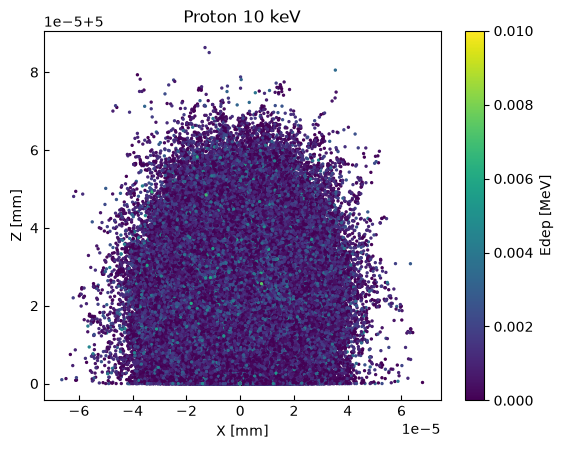

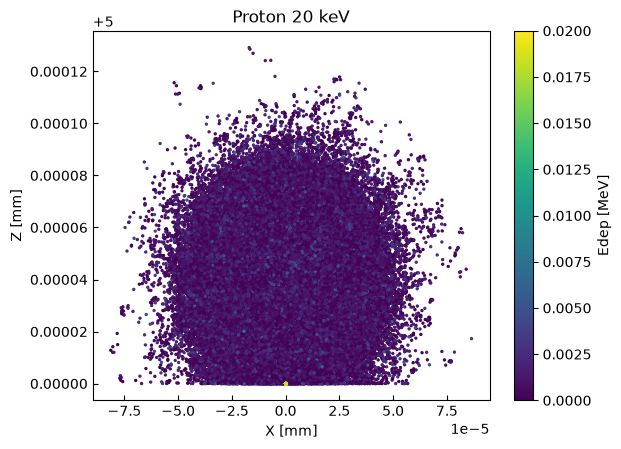

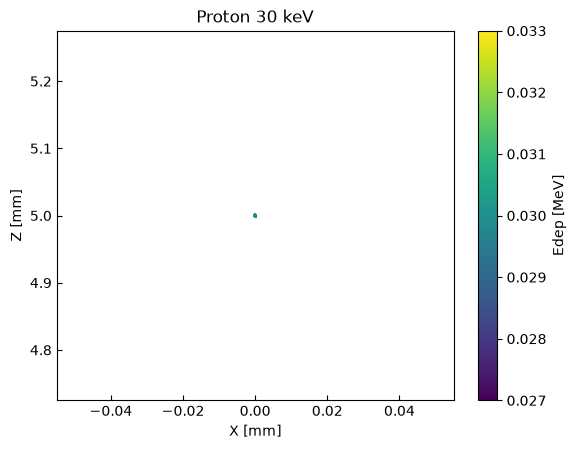

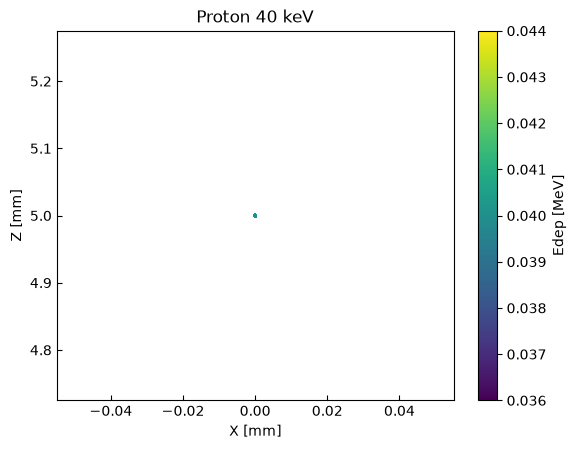

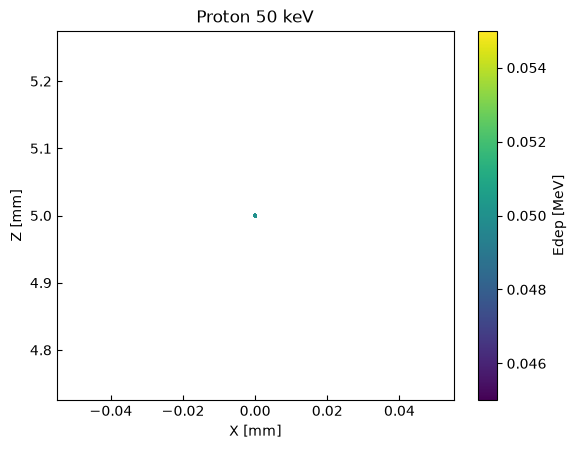

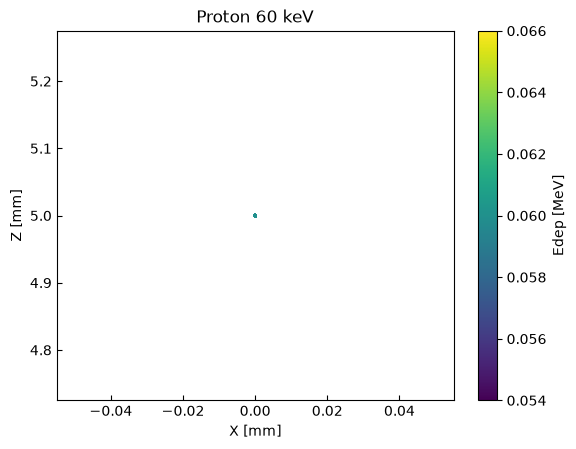

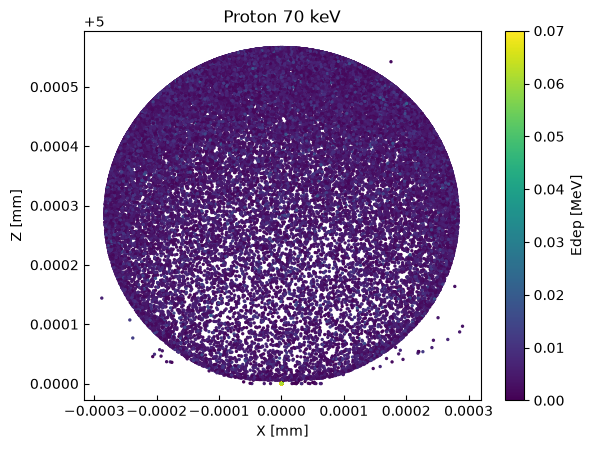

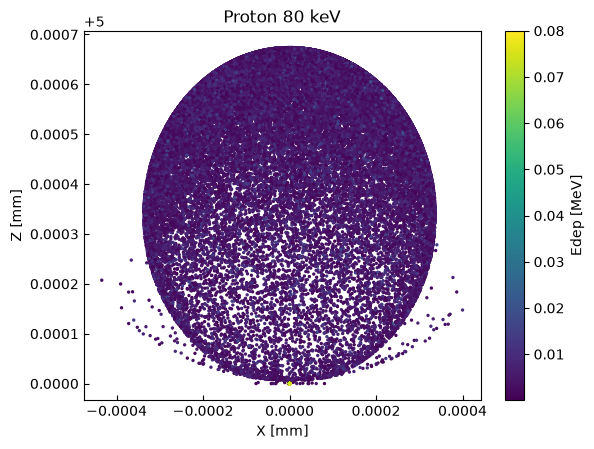

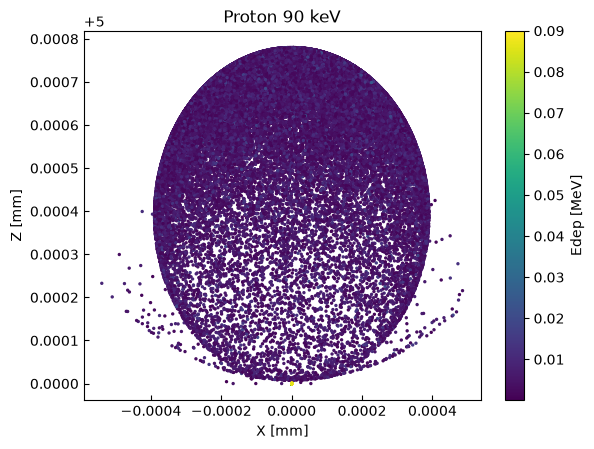

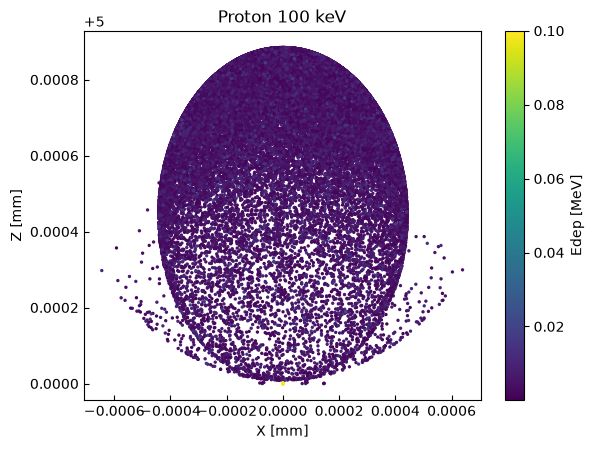

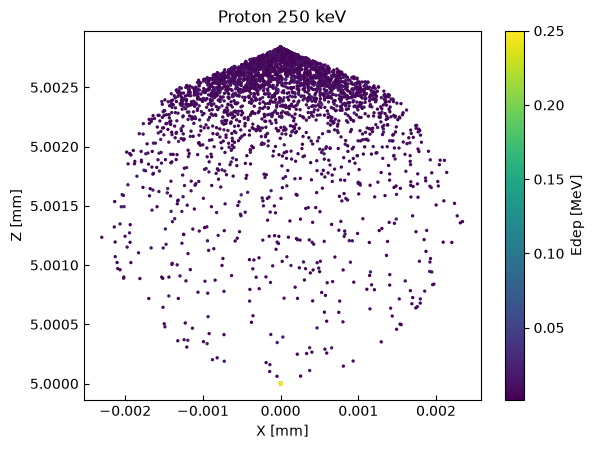

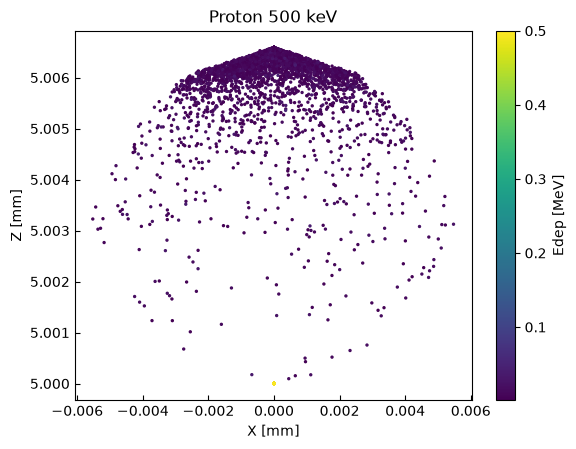

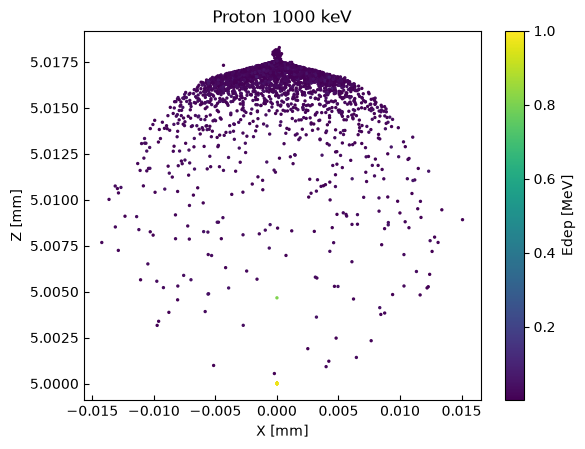

In [3]:
# plot energy depositions along the layer
for df in [Proton10keV_df, Proton20keV_df, Proton30keV_df, Proton40keV_df, Proton50keV_df, 
           Proton60keV_df, Proton70keV_df, Proton80keV_df, Proton90keV_df, Proton100keV_df, 
           Proton250keV_df, Proton500keV_df, Proton1000keV_df]:
    plt.scatter(df.x, df.z, c=df.edep, s=2)
    #width = 0.1
    #plt.xlim([-width,width])
    #plt.ylim([5.5,])
    plt.xlabel("X [mm]")
    plt.ylabel("Z [mm]")
    plt.colorbar(label="Edep [MeV]")
    plt.tick_params(axis='both' , direction='in', which='both')

    if df is Proton10keV_df:
        plt.title("Proton 10 keV")
    elif df is Proton20keV_df:
        plt.title("Proton 20 keV")
    elif df is Proton30keV_df:
        plt.title("Proton 30 keV")
    elif df is Proton40keV_df:
        plt.title("Proton 40 keV")
    elif df is Proton50keV_df:
        plt.title("Proton 50 keV")
    elif df is Proton60keV_df:
        plt.title("Proton 60 keV")
    elif df is Proton70keV_df:
        plt.title("Proton 70 keV")
    elif df is Proton80keV_df:
        plt.title("Proton 80 keV")
    elif df is Proton90keV_df:
        plt.title("Proton 90 keV")
    elif df is Proton100keV_df:
        plt.title("Proton 100 keV")
    elif df is Proton250keV_df:
        plt.title("Proton 250 keV")
    elif df is Proton500keV_df:
        plt.title("Proton 500 keV")
    elif df is Proton1000keV_df:
        plt.title("Proton 1000 keV")

    plt.show()

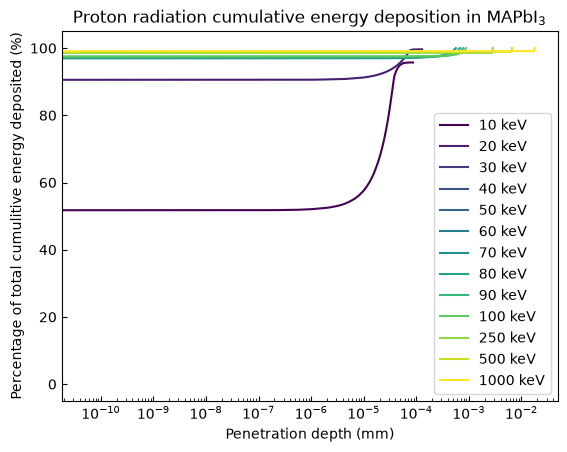

In [12]:
size = len([Proton10keV_df, Proton20keV_df, Proton30keV_df, Proton40keV_df, Proton50keV_df, 
           Proton60keV_df, Proton70keV_df, Proton80keV_df, Proton90keV_df, Proton100keV_df, 
           Proton250keV_df, Proton500keV_df, Proton1000keV_df])
colour_index = np.linspace(0, 1, size)
#print(colour_index)

cmap = plt.cm.viridis
#colour = cmap(colour_index)

colour_counter = int(0)


for df in [Proton10keV_df, Proton20keV_df, Proton30keV_df, Proton40keV_df, Proton50keV_df, 
           Proton60keV_df, Proton70keV_df, Proton80keV_df, Proton90keV_df, Proton100keV_df, 
           Proton250keV_df, Proton500keV_df, Proton1000keV_df]:
    z_list = df.z.values.tolist()
    #print(np.shape(z_list))
    #print(z_list)
    edep_list = df.edep.values.tolist()
    #print(np.shape(edep_list))
    #print(edep_list)

    total_incident_energy = np.sum(df.groupby("eid")["gen_gamma_energy"].first())#np.sum(df.true_gamma_energy)

    sorted_indices = np.argsort(z_list)
    z_list = np.array(z_list)[sorted_indices]
    z_list = z_list - 5
    edep_list = np.array(edep_list)[sorted_indices]
    edep_list = (edep_list / total_incident_energy)*100

    cum_sum_edep = np.cumsum(edep_list)
    #print(cum_sum_edep[-1])

    colour = cmap(colour_index[colour_counter])
    colour_counter += 1


    if df is Proton10keV_df:
        plt.plot(z_list, cum_sum_edep, label="10 keV", color=colour)
    elif df is Proton20keV_df:
        plt.plot(z_list, cum_sum_edep, label="20 keV", color=colour)
    elif df is Proton30keV_df:
        plt.plot(z_list, cum_sum_edep, label="30 keV", color=colour)
    elif df is Proton40keV_df:
        plt.plot(z_list, cum_sum_edep, label="40 keV", color=colour)
    elif df is Proton50keV_df:
        plt.plot(z_list, cum_sum_edep, label="50 keV", color=colour)
    elif df is Proton60keV_df:
        plt.plot(z_list, cum_sum_edep, label="60 keV", color=colour)
    elif df is Proton70keV_df:
        plt.plot(z_list, cum_sum_edep, label="70 keV", color=colour)
    elif df is Proton80keV_df:
        plt.plot(z_list, cum_sum_edep, label="80 keV", color=colour)
    elif df is Proton90keV_df:
        plt.plot(z_list, cum_sum_edep, label="90 keV", color=colour)
    elif df is Proton100keV_df:
        plt.plot(z_list, cum_sum_edep, label="100 keV", color=colour)
    elif df is Proton250keV_df:
        plt.plot(z_list, cum_sum_edep, label="250 keV", color=colour)
    elif df is Proton500keV_df:
        plt.plot(z_list, cum_sum_edep, label="500 keV", color=colour)
    elif df is Proton1000keV_df:
        plt.plot(z_list, cum_sum_edep, label="1000 keV", color=colour)

    plt.xlabel("Penetration depth (mm)")
    plt.ylabel("Percentage of total cumulitive energy deposited (%)")
    plt.legend(loc="lower right")
    plt.xscale('log')
    #plt.yscale('log')
    #plt.xlim([1*10**(-5), 10**(-2)])
    #plt.ylim([90, 101])
    #plt.ylim(72.03, 72.0375)
    #plt.xlim(7.9*10**-4 ,9 * 10**-4)
    plt.title(r"Proton radiation cumulative energy deposition in MAPbI${_3}$")
    plt.tick_params(axis='both' , direction='in', which='both')
    #plt.show()
plt.show()

In [13]:
#penetration depth as defined in that one paper as 99% of energy deposited
taper_check_number = - 200
taper_check_percentage = 99/100

pen_energy = []
penetration_depth_true = []
penetration_depth_approx = []

for df in [Proton10keV_df, Proton20keV_df, Proton30keV_df, Proton40keV_df, Proton50keV_df, 
           Proton60keV_df, Proton70keV_df, Proton80keV_df, Proton90keV_df, Proton100keV_df, 
           Proton250keV_df, Proton500keV_df, Proton1000keV_df]:
    if df is Proton10keV_df:
        name = "10"
        pen_energy.append(10)
    elif df is Proton20keV_df:
        name = "20"
        pen_energy.append(20)
    elif df is Proton30keV_df:
        name = "30"
        pen_energy.append(30)
    elif df is Proton40keV_df:
        name = "40"
        pen_energy.append(40)
    elif df is Proton50keV_df:
        name = "50"
        pen_energy.append(50)
    elif df is Proton60keV_df:
        name = "60"
        pen_energy.append(60)
    elif df is Proton70keV_df:
        name = "70"
        pen_energy.append(70)
    elif df is Proton80keV_df:
        name = "80"
        pen_energy.append(80)
    elif df is Proton90keV_df:
        name = "90"
        pen_energy.append(90)
    elif df is Proton100keV_df:
        name = "100"
        pen_energy.append(100)
    elif df is Proton250keV_df:
        name = "250"
        pen_energy.append(250)
    elif df is Proton500keV_df:
        name = "500"
        pen_energy.append(500)
    elif df is Proton1000keV_df:
        name = "1000"
        pen_energy.append(1000)

    z_list = df.z.values.tolist()
    #print(np.shape(z_list))
    #print(z_list)
    edep_list = df.edep.values.tolist()
    #print(np.shape(edep_list))
    #print(edep_list)

    total_incident_energy = np.sum(df.groupby("eid")["gen_gamma_energy"].first())#np.sum(df.true_gamma_energy)

    sorted_indices = np.argsort(z_list)
    z_list = np.array(z_list)[sorted_indices]
    z_list = z_list - 5
    z_list = z_list.tolist()
    edep_list = np.array(edep_list)[sorted_indices]
    edep_list = (edep_list / total_incident_energy)*100

    cum_sum_edep = np.cumsum(edep_list)

    pen_depth_list = []

    if cum_sum_edep[-1] > 99:
        for i, val in enumerate(cum_sum_edep):
            if val>99:
                pen_depth_list.append(z_list[i])

        pen_depth_list = np.array(pen_depth_list)
        #print(pen_depth_list)
        pen_depth = np.min(pen_depth_list)
        print(f"True penetration depth for Proton {name}keV = {pen_depth}mm")

        penetration_depth_true.append(pen_depth)
        penetration_depth_approx.append(np.nan)
    
    elif cum_sum_edep[-1] < 99:
        print(f"Warning: Cumulative energy deposition for {name} does not reach 99%. Maximum is {cum_sum_edep[-1]}%.")

        assume_100_percent = 100/cum_sum_edep[-1]
        scaled_cum_sum_edep = assume_100_percent * cum_sum_edep
        assume_99_percent = taper_check_percentage * scaled_cum_sum_edep[-1]
        
        if assume_99_percent <= scaled_cum_sum_edep[taper_check_number]:
            print(f"Radiaiton tapers off.")

            #assume_100_percent = 100/cum_sum_edep[-1]
            
            for i, val in enumerate(scaled_cum_sum_edep):
                if val>=99:
                    hello = z_list[i]
                    pen_depth_list.append(hello)

            pen_depth_list = np.array(pen_depth_list)
            pen_depth = np.min(pen_depth_list)

            print(f"Approximated penetration depth for Proton: {name}keV = {pen_depth}mm")
            penetration_depth_true.append(np.nan)
            penetration_depth_approx.append(pen_depth)

        elif assume_99_percent > scaled_cum_sum_edep[taper_check_number]:
            print(f"Radiation does not taper off. Penetration depth >1mm. Scaled 99% is {assume_99_percent}; {- taper_check_number} points back the cumsum is {scaled_cum_sum_edep[taper_check_number]}.")
            penetration_depth_true.append(np.nan)
            penetration_depth_approx.append(np.nan)

        else:
            print("Error in tapering")

    else:
        print("Error. Somehow the final item of cum_sum_edep is not > or < to 99")
    print("~")

Radiaiton tapers off.
Approximated penetration depth for Proton: 10keV = 4.787143807316596e-05mm
~
True penetration depth for Proton 20keV = 7.343171369722512e-05mm
~
True penetration depth for Proton 30keV = 0.0mm
~
True penetration depth for Proton 40keV = 0.0mm
~
True penetration depth for Proton 50keV = 0.0mm
~
True penetration depth for Proton 60keV = 0.0mm
~
True penetration depth for Proton 70keV = 0.00047939558505127877mm
~
True penetration depth for Proton 80keV = 0.0005794379485752899mm
~
True penetration depth for Proton 90keV = 0.0006767348205487522mm
~
True penetration depth for Proton 100keV = 0.000775048856654692mm
~
True penetration depth for Proton 250keV = 0.0028357668016925075mm
~
True penetration depth for Proton 500keV = 0.006590241855496615mm
~
True penetration depth for Proton 1000keV = 0.0mm
~


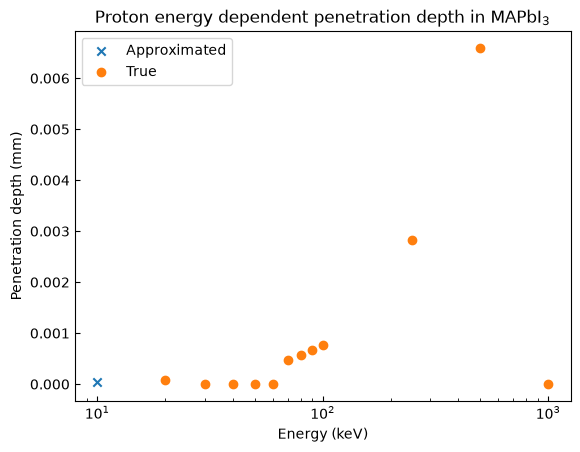

In [14]:
plt.scatter(pen_energy, penetration_depth_approx, marker='x', label="Approximated")
plt.scatter(pen_energy, penetration_depth_true, marker='o', label="True")
plt.title(r"Proton energy dependent penetration depth in MAPbI${_3}$")
plt.xlabel("Energy (keV)")
plt.ylabel("Penetration depth (mm)")
plt.tick_params(axis='both' , direction='in', which='both')
plt.legend()#loc="upper right")
plt.xscale("log")
#plt.xlim(0, 105)